# Selective filters: a guided demo

This notebook walks through the main results behind the `selective_filters` package:

1. Smoothing a noisy signal
2. The exact reduction: Odd-Even is one FIR kernel
3. Frequency response: never negative
4. Partitions, including data-dependent ones
5. Choosing the width: moments and Gaussian limit
6. Picking the smoothing level from the data
7. Multiplier-free bandpass filters
8. Streaming signals

A **selective step** replaces a chosen set of target samples by the mean of their neighbours at prescribed lags and leaves the rest unchanged. The **Odd-Even** filter applies the step to the odd and to the even samples of the same input and averages the two outputs.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.signal import savgol_coeffs

from selective_filters import (
    selective_filter, apply_selective_filter, apply_selective_filter_stream,
    odd_even_impulse_response, odd_even_frequency_response, odd_even_moments,
    apply_odd_even_bandpass, odd_even_bandpass_frequency_response, odd_even_bandpass_properties,
)

plt.rcParams.update({"figure.figsize": (8, 3), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.default_rng(0)

## 1. Smoothing a noisy signal

A sine with noise, smoothed by the Odd-Even filter (lag sweep 5, 4, …, 1), by the nonlinear Max-Min member, and by a Gaussian filter of the same width.

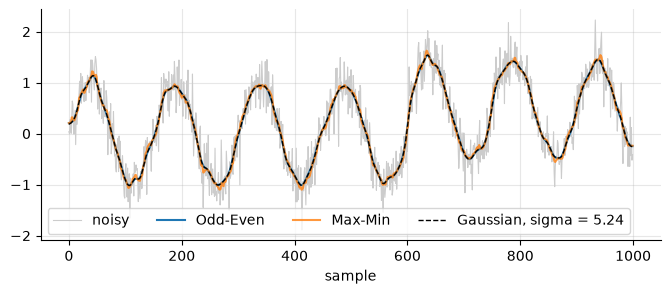

Odd-Even  RMS error: 0.0718
Max-Min   RMS error: 0.0854
Gaussian  RMS error: 0.0724


In [ ]:
t = np.arange(1000)
clean = np.sin(2 * np.pi * t / 150) + 0.5 * (t > 600)
y = clean + 0.3 * rng.standard_normal(t.size)

lags, R, sweep = [1, 5], 1, "descending"
odd_even = apply_selective_filter(y, "Odd-Even", lags, R, sweep, include_borders=True)
max_min = apply_selective_filter(y, "Max-Min", lags, R, sweep, include_borders=True)
sigma = odd_even_moments(lags, R, sweep)["sigma"]
gauss = gaussian_filter1d(y, sigma, mode="reflect")

plt.plot(t, y, color="0.8", lw=0.8, label="noisy")
plt.plot(t, odd_even, label="Odd-Even")
plt.plot(t, max_min, label="Max-Min", alpha=0.8)
plt.plot(t, gauss, "--", color="k", lw=1, label=f"Gaussian, sigma = {sigma:.2f}")
plt.legend(ncol=4, loc="lower left"); plt.xlabel("sample"); plt.show()

for name, out in [("Odd-Even", odd_even), ("Max-Min", max_min), ("Gaussian", gauss)]:
    print(f"{name:9s} RMS error: {np.sqrt(np.mean((out - clean)[20:-20] ** 2)):.4f}")

Odd-Even and the Gaussian are almost indistinguishable: Section 5 shows why.

## 2. The exact reduction

At a sample n, one of the two steps replaces y[n] by the neighbour mean and the other leaves it unchanged. Averaging the two outputs at the same n gives, for lag k,

$$y[n] \leftarrow \tfrac12 y[n] + \tfrac14\,(y[n-k] + y[n+k]),$$

the same three-tap kernel at every sample: the selection cancels. The filter is centred on n, so there is no delay.

In [ ]:
k = 2
one_step = apply_selective_filter(y, "Odd-Even", [k, k], 1, "none", True)
n = np.arange(k, len(y) - k)
print("max |Odd-Even step - (y/2 + (y[n-k] + y[n+k])/4)|:",
      np.abs(one_step[n] - (y[n] / 2 + (y[n - k] + y[n + k]) / 4)).max())

# Each step alone is not shift-invariant: shifting the input by one sample changes the output
odd = lambda v: selective_filter(v, "Odd", [1, 1], True)
print("Odd step, shift then filter vs filter then shift:", np.abs(odd(np.roll(y, 1))[5:-5] - np.roll(odd(y), 1)[5:-5]).max())

max |Odd-Even step - (y/2 + (y[n-k] + y[n+k])/4)|: 0.0
Odd step, shift then filter vs filter then shift: 1.2544180649110372


Repeats and lag sweeps are compositions of such steps, so the whole filter is a single zero-phase FIR kernel. Its impulse response is known in closed form; the circles are the output of the selective algorithm for a unit impulse.

[1, 5]  R=1 descending: max |algorithm - closed form| = 0.0e+00
[2, 4]  R=3 none      : max |algorithm - closed form| = 5.6e-17
[0, 3]  R=4 none      : max |algorithm - closed form| = 2.8e-17


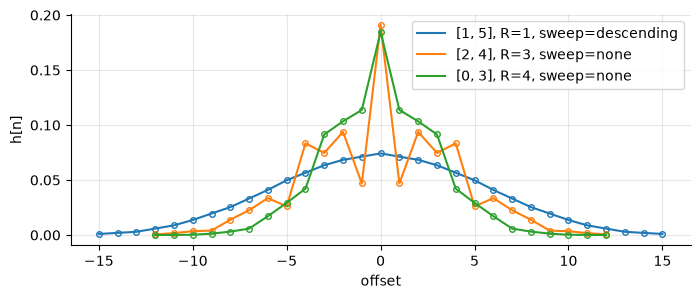

ascending vs descending sweep, max difference: 4.440892098500626e-16


In [ ]:
x = np.zeros(201); x[100] = 1
fig, ax = plt.subplots()
for lags_, R_, sweep_ in [([1, 5], 1, "descending"), ([2, 4], 3, "none"), ([0, 3], 4, "none")]:
    nn, h = odd_even_impulse_response(lags_, R_, sweep_)
    out = apply_selective_filter(x, "Odd-Even", lags_, R_, sweep_, True)
    line, = ax.plot(nn, h, label=f"{lags_}, R={R_}, sweep={sweep_}")
    ax.plot(nn, out[100 + nn], "o", mfc="none", ms=4, color=line.get_color())
    print(f"{str(lags_):7s} R={R_} {sweep_:10s}: max |algorithm - closed form| = {np.abs(out[100 + nn] - h).max():.1e}")
ax.set_xlabel("offset"); ax.set_ylabel("h[n]"); ax.legend(); plt.show()

up = apply_selective_filter(y, "Odd-Even", [1, 6], 2, "ascending", True)
down = apply_selective_filter(y, "Odd-Even", [1, 6], 2, "descending", True)
print("ascending vs descending sweep, max difference:", np.abs(up - down)[50:-50].max())

## 3. Frequency response: never negative

Each lag-k step has response cos²(kω/2), so every Odd-Even design has a response in [0, 1]: no band is ever inverted or amplified. A Savitzky–Golay smoother of similar width, for comparison, has negative lobes that flip the sign of some frequencies.

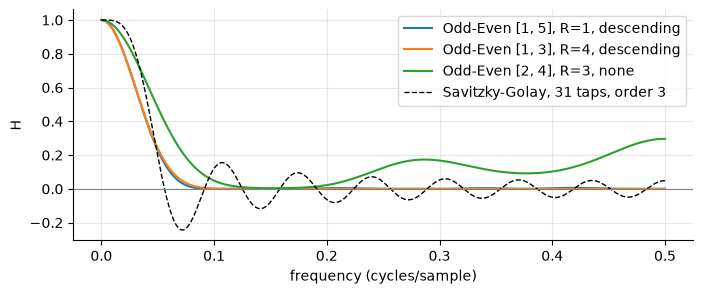

minimum response, Savitzky-Golay: -0.244


In [ ]:
w = np.linspace(0, np.pi, 2000); f = w / (2 * np.pi)
fig, ax = plt.subplots()
for lags_, R_, sweep_ in [([1, 5], 1, "descending"), ([1, 3], 4, "descending"), ([2, 4], 3, "none")]:
    ax.plot(f, odd_even_frequency_response(w, lags_, R_, sweep_), label=f"Odd-Even {lags_}, R={R_}, {sweep_}")
sg = savgol_coeffs(31, 3)
H_sg = (sg[None, :] * np.cos(np.outer(w, np.arange(-15, 16)))).sum(axis=1)
ax.plot(f, H_sg, "k--", lw=1, label="Savitzky-Golay, 31 taps, order 3")
ax.axhline(0, color="0.5", lw=0.8)
ax.set_xlabel("frequency (cycles/sample)"); ax.set_ylabel("H"); ax.legend(); plt.show()
print("minimum response, Savitzky-Golay:", H_sg.min().round(3))

## 4. Partitions, including data-dependent ones

The cancellation only needs the target sets to partition the samples. For K sets,

$$\frac1K \sum_k F_{T_k} = \frac1K\,[A + (K-1) I],$$

even when the partition depends on the data. Averaging the steps on the local maxima, the local minima and all remaining samples (K = 3) is exactly linear, while the Max-Min member, which averages only the first two, is not.

In [ ]:
lags_ = [1, 3]
Ay = selective_filter(y, "All", lags_, True)          # every sample replaced: A y
yb = np.pad(y, 1, mode="reflect")
is_max = (y >= yb[:-2]) & (y >= yb[2:])
is_min = (y <= yb[:-2]) & (y <= yb[2:])
rest = ~(is_max | is_min)
three = np.mean([np.where(m, Ay, y) for m in (is_max, is_min, rest)], axis=0)
print("Max/Min/rest average vs (A y + 2 y)/3:", np.abs(three - (Ay + 2 * y) / 3).max())

# Superposition test: f(a + b) = f(a) + f(b) holds only for linear filters
a, b = rng.standard_normal(500), rng.standard_normal(500)
for target in ("Odd-Even", "Max-Min"):
    f_ = lambda v: apply_selective_filter(v, target, lags_, 1, "none", True)
    print(f"{target:8s} superposition error: {np.abs(f_(a + b) - f_(a) - f_(b)).max():.1e}")

Max/Min/rest average vs (A y + 2 y)/3: 4.440892098500626e-16
Odd-Even superposition error: 3.3e-16
Max-Min  superposition error: 1.3e+00


## 5. Choosing the width

The variance of the kernel is σ² = R/2 · Σk² for a sweep, so the width is known before filtering. Repeats push the kernel towards a Gaussian of the same variance.

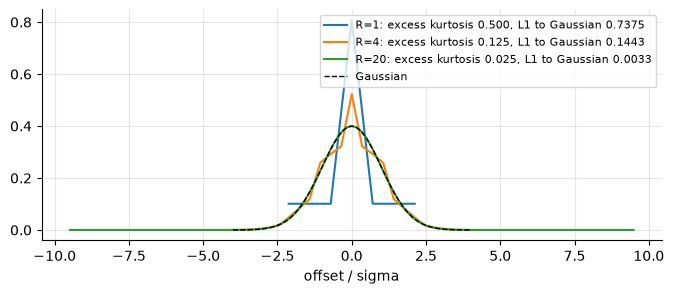

In [ ]:
fig, ax = plt.subplots()
for R_ in (1, 4, 20):
    nn, h = odd_even_impulse_response([0, 3], R_, "none")
    m = odd_even_moments([0, 3], R_, "none")
    g = np.exp(-nn**2 / (2 * m["variance"])); g /= g.sum()
    ax.plot(nn / m["sigma"], h * m["sigma"], label=f"R={R_}: excess kurtosis {m['excess_kurtosis']:.3f}, L1 to Gaussian {np.abs(h - g).sum():.4f}")
z = np.linspace(-4, 4, 400)
ax.plot(z, np.exp(-z**2 / 2) / np.sqrt(2 * np.pi), "k--", lw=1, label="Gaussian")
ax.set_xlabel("offset / sigma"); ax.legend(fontsize=8); plt.show()

## 6. Picking the smoothing level from the data

On a regular grid the filter is a linear smoother ŷ = S y whose diagonal is the centre tap h[0], so the leave-one-out and generalised cross-validation scores are available in closed form without refitting:

$$\mathrm{GCV} = \frac{\overline{(y - \hat y)^2}}{(1 - h[0])^2}.$$

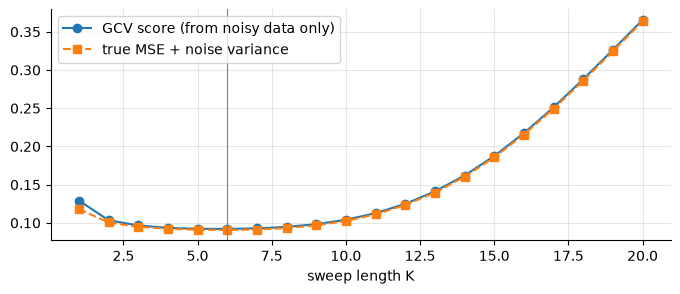

GCV picks K = 6; the best K against the clean signal is 6


In [ ]:
K_values = np.arange(1, 21)
gcv, err = [], []
for K in K_values:
    nn, h = odd_even_impulse_response([1, K], 1, "descending")
    yh = apply_selective_filter(y, "Odd-Even", [1, K], 1, "descending", True)
    gcv.append(np.mean((y - yh)[30:-30] ** 2) / (1 - h[nn == 0][0]) ** 2)
    err.append(np.sqrt(np.mean((yh - clean)[30:-30] ** 2)))
best = K_values[np.argmin(gcv)]
fig, ax = plt.subplots()
ax.plot(K_values, gcv, "o-", label="GCV score (from noisy data only)")
ax.plot(K_values, np.square(err) + np.var(y - clean), "s--", label="true MSE + noise variance")
ax.axvline(best, color="0.5", lw=0.8)
ax.set_xlabel("sweep length K"); ax.legend(); plt.show()
print(f"GCV picks K = {best}; the best K against the clean signal is {K_values[np.argmin(err)]}")

## 7. Multiplier-free bandpass filters

Highpass steps y − (lowpass step) have response sin²(kω/2). Products of lowpass and highpass steps, or differences of two sweeps, give bandpass filters built from additions and shifts only.

product r=2, s=2               centre 0.250, -3 dB band 0.185-0.315 cycles/sample
product r=4, s=1, dilation 3   centre 0.047, -3 dB band 0.029-0.066 cycles/sample
difference [1,2] - [1,6], R=2  centre 0.041, -3 dB band 0.023-0.074 cycles/sample


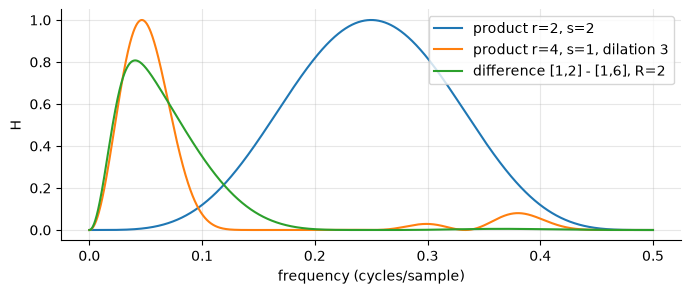

product r=2, s=2 keeps the 0.25 tone (amplitude 1.0 ) and removes the 0.02 tone


In [ ]:
fig, ax = plt.subplots()
designs = {"product r=2, s=2": dict(method="product", r=2, s=2),
           "product r=4, s=1, dilation 3": dict(method="product", r=4, s=1, dilation=3, image_lags=(1, 2)),
           "difference [1,2] - [1,6], R=2": dict(method="difference", lags_a=(1, 2), lags_b=(1, 6), repeats=2)}
for name, kw in designs.items():
    ax.plot(f, odd_even_bandpass_frequency_response(w, **kw), label=name)
    p = odd_even_bandpass_properties(**kw)
    print(f"{name:30s} centre {p['centre']:.3f}, -3 dB band {p['low_3db']:.3f}-{p['high_3db']:.3f} cycles/sample")
ax.set_xlabel("frequency (cycles/sample)"); ax.set_ylabel("H"); ax.legend(); plt.show()

tone = np.sin(2 * np.pi * 0.25 * t) + np.sin(2 * np.pi * 0.02 * t)
out = apply_odd_even_bandpass(tone, method="product", r=2, s=2)
print("product r=2, s=2 keeps the 0.25 tone (amplitude", round(np.abs(out[100:-100]).max(), 3),
      ") and removes the 0.02 tone")

## 8. Streaming signals

An output sample depends only on inputs within a finite radius, so a continuous signal can be filtered block by block (overlap-save). The result is identical to filtering the whole signal, for every target, including the nonlinear ones.

In [ ]:
blocks = np.array_split(y, 37)
for target in ("Odd-Even", "Max-Min"):
    streamed = np.concatenate(list(apply_selective_filter_stream(blocks, target, [1, 4], 2, "descending", True)))
    batch = apply_selective_filter(y, target, [1, 4], 2, "descending", True)
    print(f"{target:8s} streamed vs whole signal, max difference: {np.abs(streamed - batch).max():.1e}")

Odd-Even streamed vs whole signal, max difference: 0.0e+00


Max-Min  streamed vs whole signal, max difference: 0.0e+00
